# Multi-Dataset Student Stress Analysis
## Comprehensive Analysis of Combined Datasets

This notebook analyzes four combined datasets:
1. Student Stress Factors (2).csv - Original dataset
2. StressLevelDataset.csv - Additional stress data
3. Stress_Dataset.csv - Comprehensive stress survey
4. user_inputs.csv - User-contributed data from API


---

In [19]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

## 1. Load All Datasets

In [20]:
# Load the combined processed dataset
try:
    combined_df = pd.read_csv('../data/processed/combined_dataset.csv')
    print("✓ Loaded combined dataset from processed folder")
except:
    print("Combined dataset not found. Loading individual datasets...")
    # Load individual datasets
    df1 = pd.read_csv('../Student Stress Factors (2).csv')
    df2 = pd.read_csv('../StressLevelDataset.csv')
    df3 = pd.read_csv('../Stress_Dataset.csv')
    print(f"Dataset 1: {df1.shape}")
    print(f"Dataset 2: {df2.shape}")
    print(f"Dataset 3: {df3.shape}")

print(f"\nCombined Dataset Shape: {combined_df.shape}")
print(f"\nColumns: {combined_df.columns.tolist()}")
combined_df.head()

✓ Loaded combined dataset from processed folder

Combined Dataset Shape: (1363, 10)

Columns: ['sleep_quality', 'headaches_per_week', 'academic_performance', 'study_load', 'extracurricular_frequency', 'stress_level', 'dataset_source', 'wellbeing_score', 'academic_pressure', 'total_workload']


,sleep_quality,headaches_per_week,academic_performance,study_load,extracurricular_frequency,stress_level,dataset_source,wellbeing_score,academic_pressure,total_workload
0,3.0,1.0,3.0,4.0,2.0,3,student_factors,2.5,12.0,5.0
1,4.0,1.0,2.0,3.0,3.0,2,student_factors,3.5,12.0,4.5
2,2.0,1.0,2.0,1.0,4.0,4,student_factors,1.5,4.0,3.0
3,3.0,2.0,3.0,2.0,3.0,3,student_factors,2.0,6.0,3.5
4,2.0,3.0,1.0,5.0,5.0,3,student_factors,0.5,25.0,7.5


## 2. Dataset Overview & Statistics

In [21]:
# Basic statistics
print("=== Dataset Information ===")
print(f"Total Samples: {len(combined_df)}")
print(f"Total Features: {len(combined_df.columns)}")
print(f"\nMissing Values:\n{combined_df.isnull().sum()}")
print(f"\nData Types:\n{combined_df.dtypes}")

=== Dataset Information ===
Total Samples: 1363
Total Features: 10

Missing Values:
sleep_quality                0
headaches_per_week           0
academic_performance         0
study_load                   0
extracurricular_frequency    0
stress_level                 0
dataset_source               0
wellbeing_score              0
academic_pressure            0
total_workload               0
dtype: int64

Data Types:
sleep_quality                float64
headaches_per_week           float64
academic_performance         float64
study_load                   float64
extracurricular_frequency    float64
stress_level                   int64
dataset_source                object
wellbeing_score              float64
academic_pressure            float64
total_workload               float64
dtype: object


=== Dataset Source Distribution ===
dataset_source
comprehensive_stress    843
student_factors         520
Name: count, dtype: int64

⚠ No user-contributed data yet


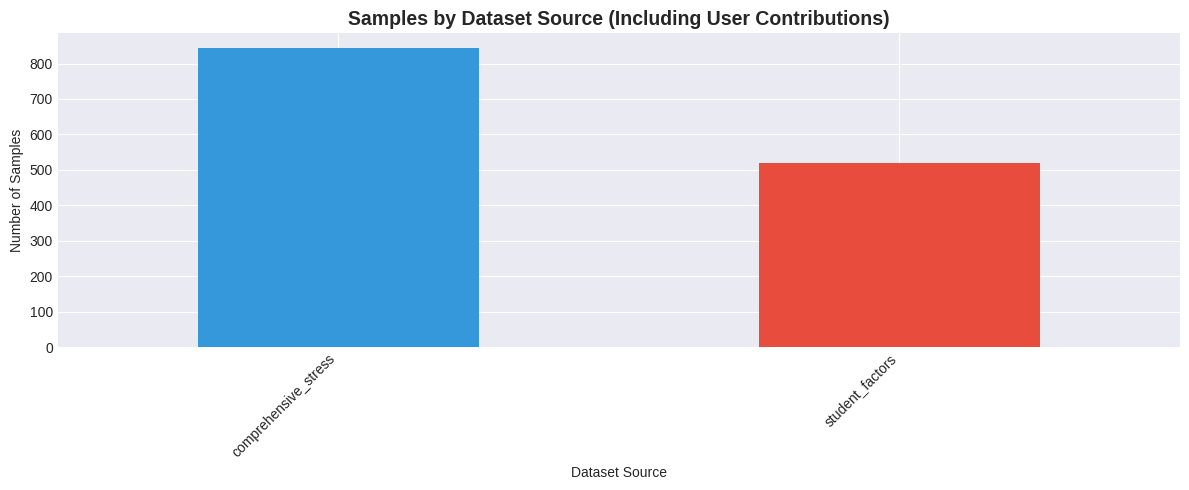

In [22]:
# Dataset source distribution
print("=== Dataset Source Distribution ===")
source_counts = combined_df['dataset_source'].value_counts()
print(source_counts)

# Check if user-contributed data exists
has_user_data = 'user_contributed' in combined_df['dataset_source'].values
if has_user_data:
    print(f"\n✓ User-contributed data found: {source_counts.get('user_contributed', 0)} samples")
else:
    print("\n⚠ No user-contributed data yet")

plt.figure(figsize=(12, 5))
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']
combined_df['dataset_source'].value_counts().plot(kind='bar', color=colors[:len(source_counts)])
plt.title('Samples by Dataset Source (Including User Contributions)', fontsize=14, fontweight='bold')
plt.xlabel('Dataset Source')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('dataset_source_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
# Statistical summary
print("=== Statistical Summary ===")
combined_df.describe()

=== Statistical Summary ===


,sleep_quality,headaches_per_week,academic_performance,study_load,extracurricular_frequency,stress_level,wellbeing_score,academic_pressure,total_workload
count,1363.000000,1363.000000,1363.000000,1363.000000,1363.000000,1363.00000,1363.000000,1363.000000,1363.000000
mean,3.179751,3.895084,3.349376,2.679971,4.425776,2.34923,1.232208,7.349200,4.892859
std,1.206006,1.988217,0.852907,1.009341,1.935178,0.99918,1.624938,4.177503,1.493983
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,-2.500000,1.000000,1.500000
25%,2.000000,2.000000,3.000000,2.000000,3.000000,2.00000,0.000000,4.000000,4.000000
50%,3.000000,4.000000,3.400000,2.600000,4.666667,2.00000,1.500000,6.760000,5.000000
75%,4.000000,6.000000,4.000000,3.200000,6.000000,2.00000,2.500000,9.000000,6.000000
max,5.000000,7.000000,5.000000,5.000000,7.000000,5.00000,4.500000,25.000000,8.500000


## 3. Stress Level Distribution Analysis

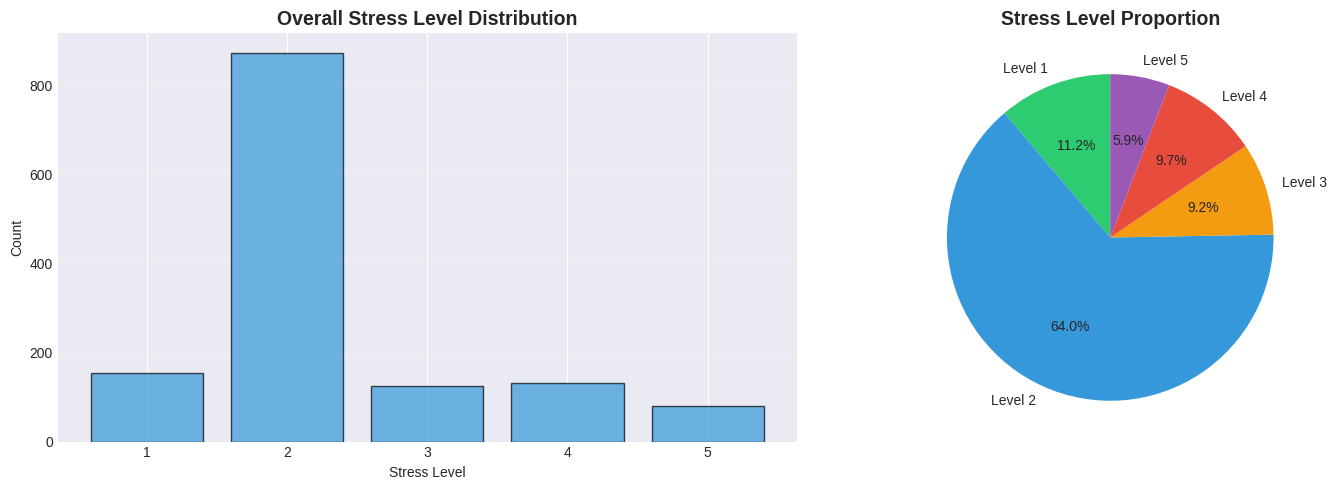

Stress Level Counts:
stress_level
1    153
2    873
3    125
4    132
5     80
Name: count, dtype: int64


In [24]:
# Overall stress level distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bar plot
stress_counts = combined_df['stress_level'].value_counts().sort_index()
axes[0].bar(stress_counts.index, stress_counts.values, color='#3498db', alpha=0.7, edgecolor='black')
axes[0].set_title('Overall Stress Level Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Stress Level')
axes[0].set_ylabel('Count')
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
colors = ['#2ecc71', '#3498db', '#f39c12', '#e74c3c', '#9b59b6']
axes[1].pie(stress_counts.values, labels=[f'Level {int(i)}' for i in stress_counts.index], 
            autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Stress Level Proportion', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('overall_stress_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Stress Level Counts:")
print(stress_counts)

<Figure size 1200x600 with 0 Axes>

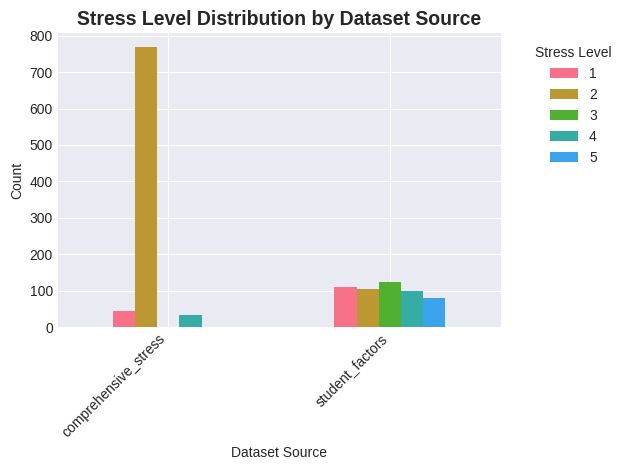

In [25]:
# Stress level by dataset source
plt.figure(figsize=(12, 6))
pd.crosstab(combined_df['dataset_source'], combined_df['stress_level']).plot(kind='bar', stacked=False)
plt.title('Stress Level Distribution by Dataset Source', fontsize=14, fontweight='bold')
plt.xlabel('Dataset Source')
plt.ylabel('Count')
plt.legend(title='Stress Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('stress_by_dataset_source.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Feature Distributions

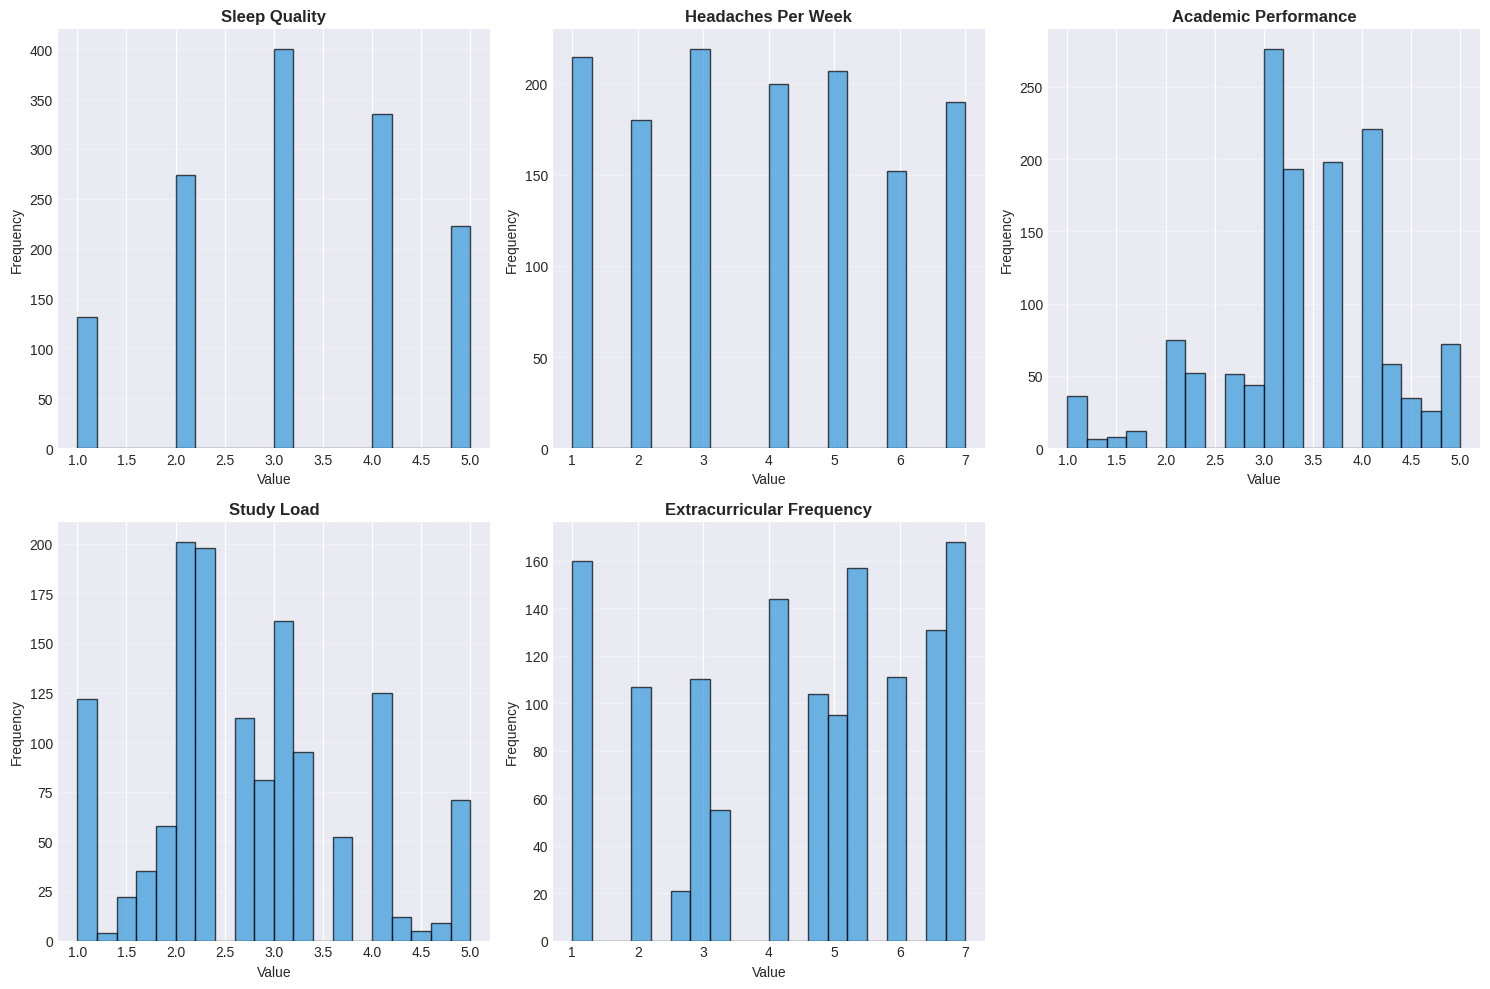

In [26]:
# Distribution of all numeric features
numeric_features = ['sleep_quality', 'headaches_per_week', 'academic_performance', 
                   'study_load', 'extracurricular_frequency']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, feature in enumerate(numeric_features):
    axes[idx].hist(combined_df[feature], bins=20, color='#3498db', alpha=0.7, edgecolor='black')
    axes[idx].set_title(f'{feature.replace("_", " ").title()}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Value')
    axes[idx].set_ylabel('Frequency')
    axes[idx].grid(axis='y', alpha=0.3)

# Hide the last subplot if not needed
axes[-1].axis('off')

plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Correlation Analysis

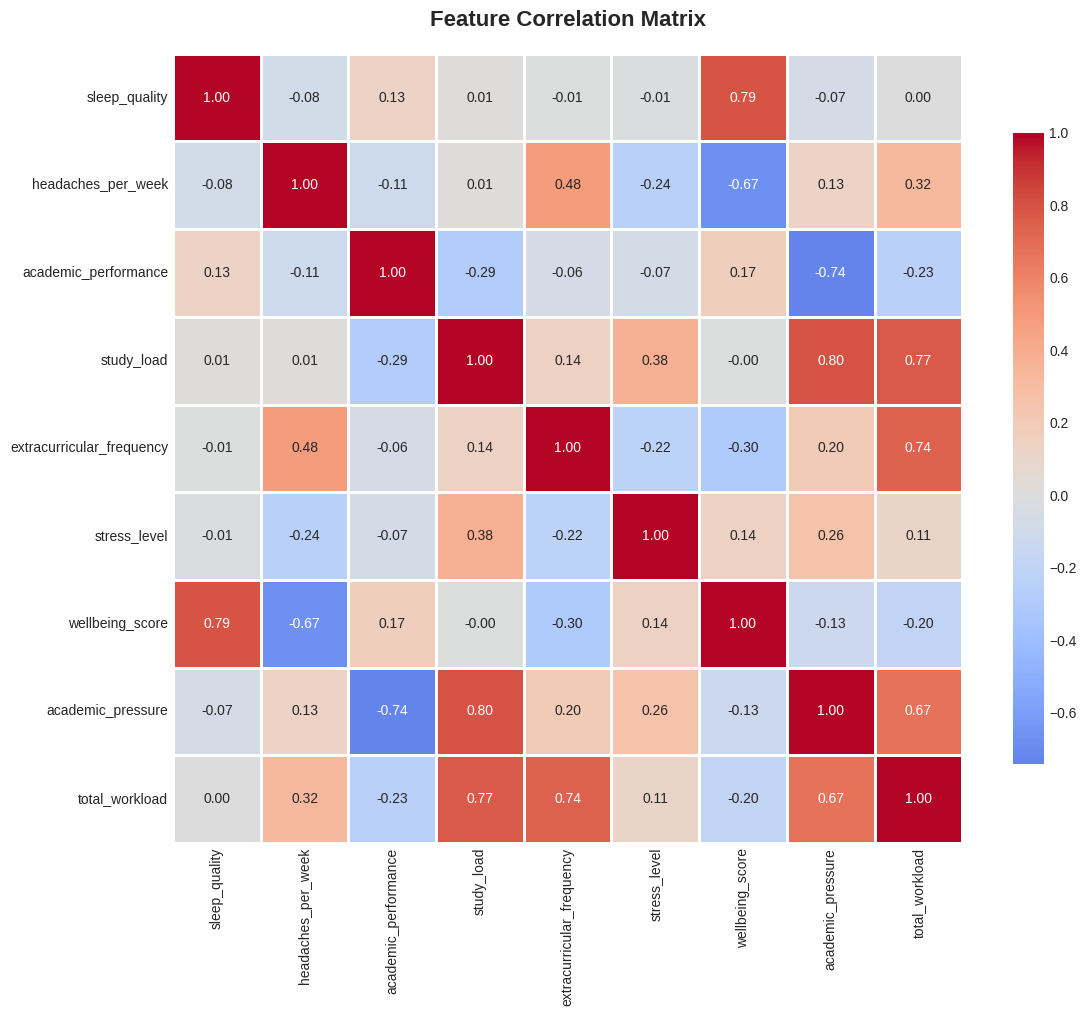


Strongest Correlations with Stress Level:
stress_level                 1.000000
study_load                   0.380268
academic_pressure            0.261354
wellbeing_score              0.140398
total_workload               0.113945
sleep_quality               -0.010700
academic_performance        -0.070046
extracurricular_frequency   -0.220742
headaches_per_week          -0.242471
Name: stress_level, dtype: float64


In [27]:
# Correlation matrix
correlation_features = ['sleep_quality', 'headaches_per_week', 'academic_performance', 
                       'study_load', 'extracurricular_frequency', 'stress_level']

if 'wellbeing_score' in combined_df.columns:
    correlation_features.extend(['wellbeing_score', 'academic_pressure', 'total_workload'])

correlation_matrix = combined_df[correlation_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('correlation_matrix_multi_dataset.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nStrongest Correlations with Stress Level:")
stress_corr = correlation_matrix['stress_level'].sort_values(ascending=False)
print(stress_corr)

## 6. Feature vs Stress Level Analysis

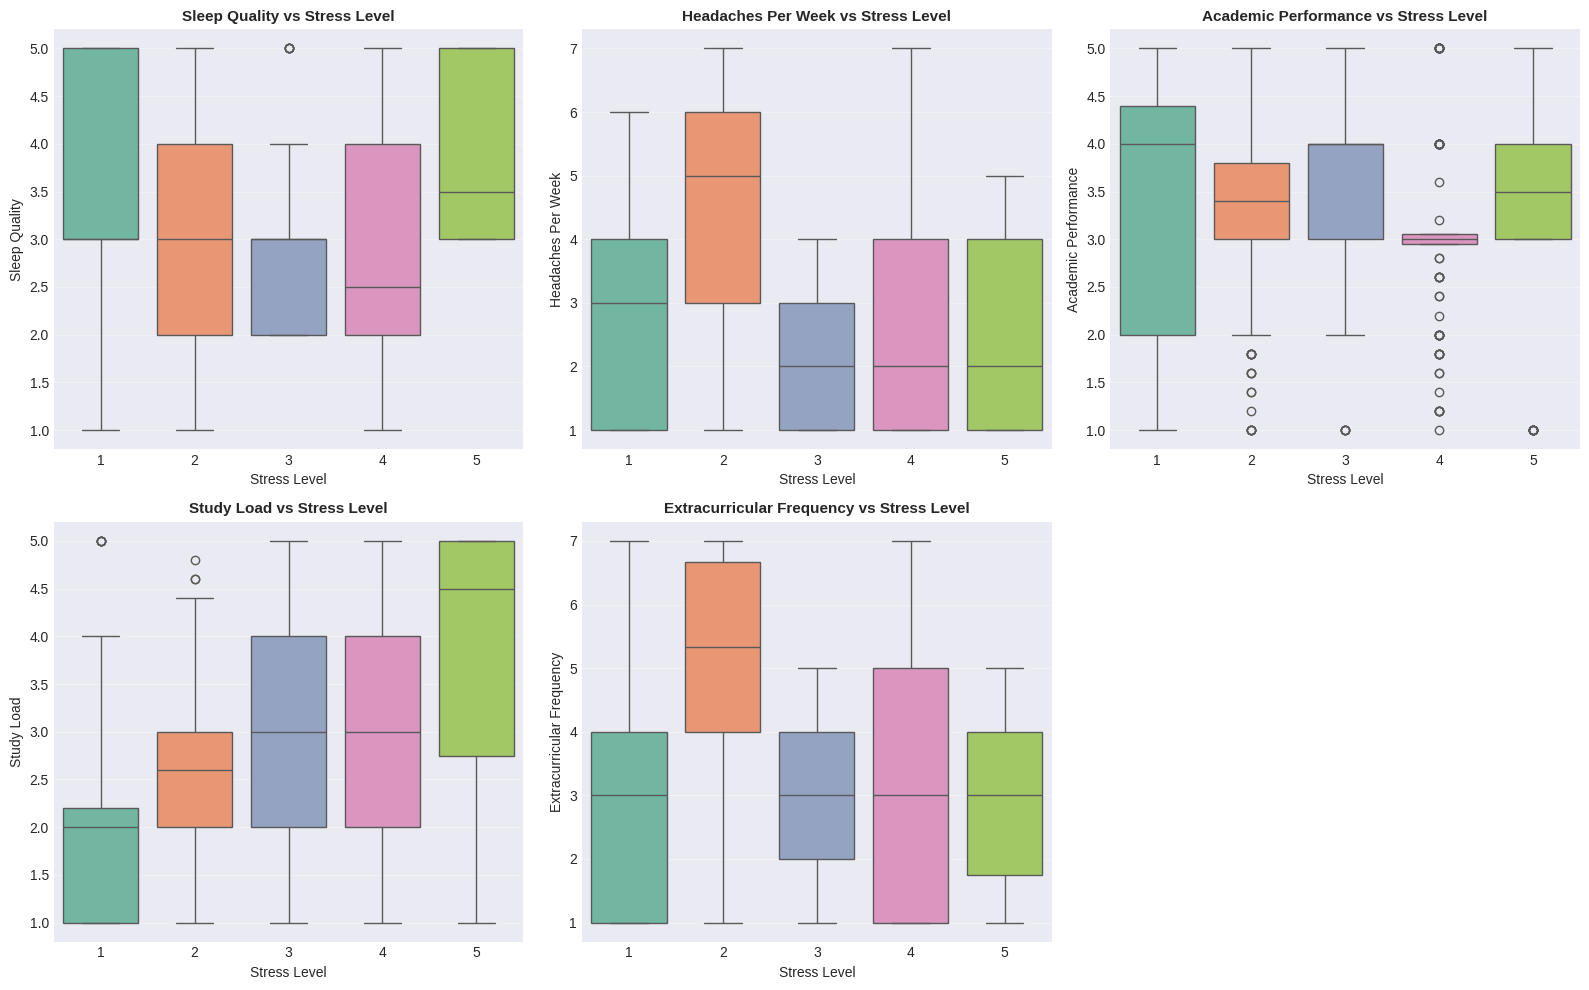

In [28]:
# Box plots for each feature vs stress level
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, feature in enumerate(numeric_features):
    sns.boxplot(data=combined_df, x='stress_level', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'{feature.replace("_", " ").title()} vs Stress Level', 
                       fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Stress Level')
    axes[idx].set_ylabel(feature.replace('_', ' ').title())
    axes[idx].grid(axis='y', alpha=0.3)

axes[-1].axis('off')

plt.tight_layout()
plt.savefig('features_vs_stress_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

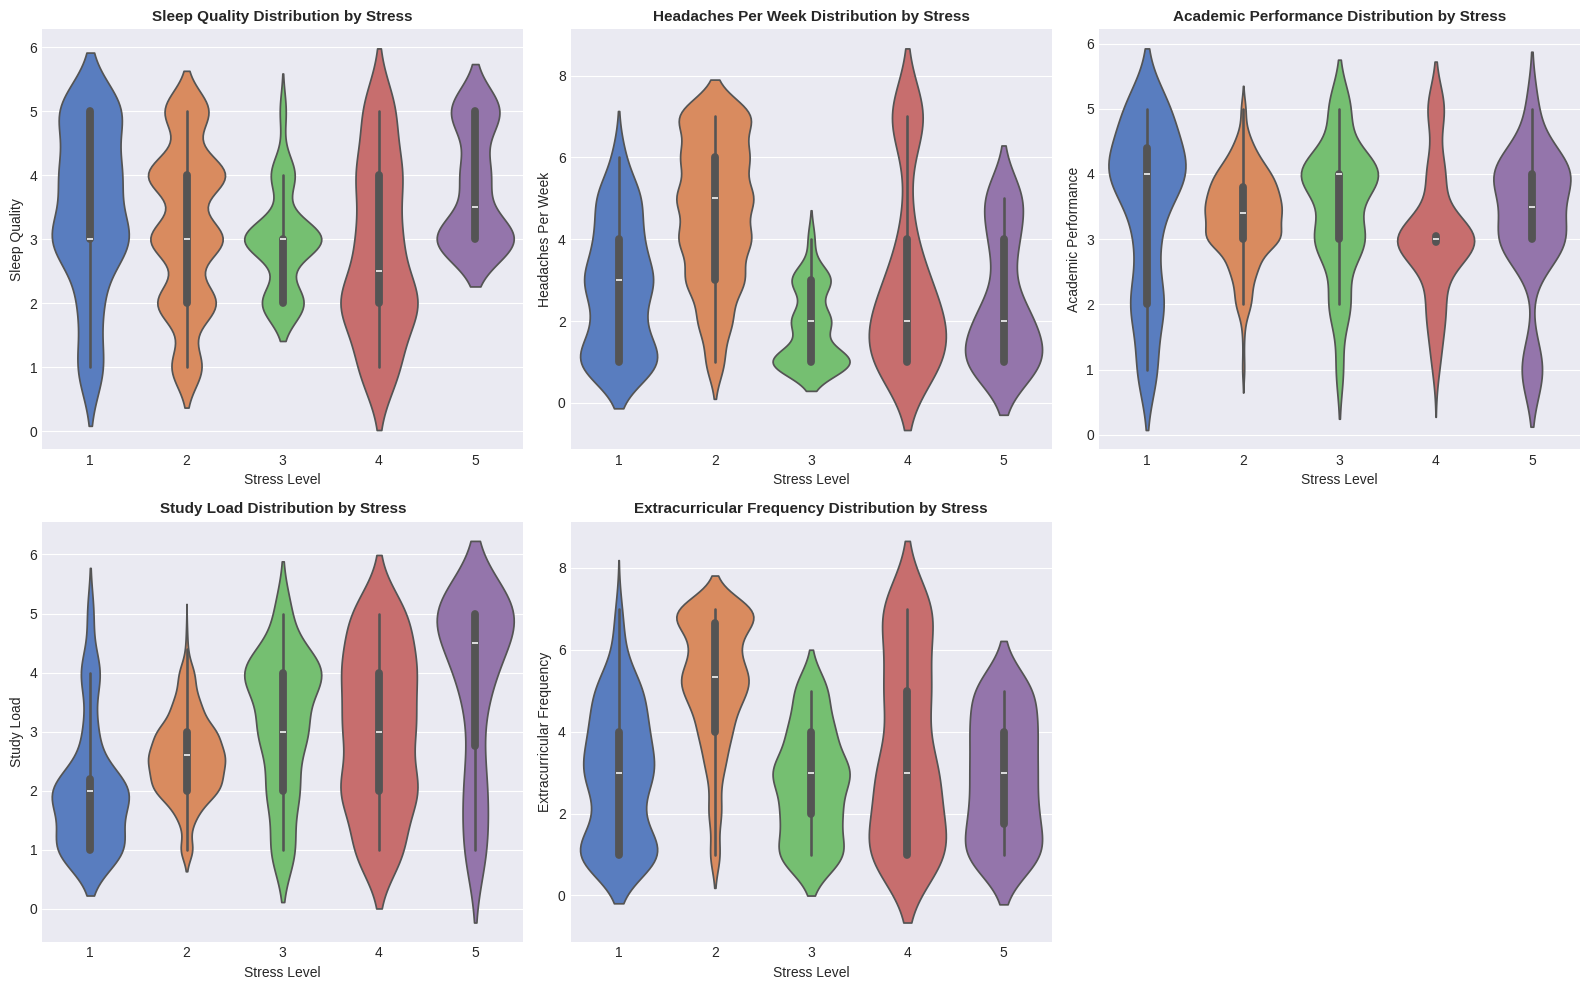

In [29]:
# Violin plots for better distribution visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, feature in enumerate(numeric_features):
    sns.violinplot(data=combined_df, x='stress_level', y=feature, ax=axes[idx], palette='muted')
    axes[idx].set_title(f'{feature.replace("_", " ").title()} Distribution by Stress', 
                       fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Stress Level')
    axes[idx].set_ylabel(feature.replace('_', ' ').title())

axes[-1].axis('off')

plt.tight_layout()
plt.savefig('features_vs_stress_violins.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Engineered Features Analysis

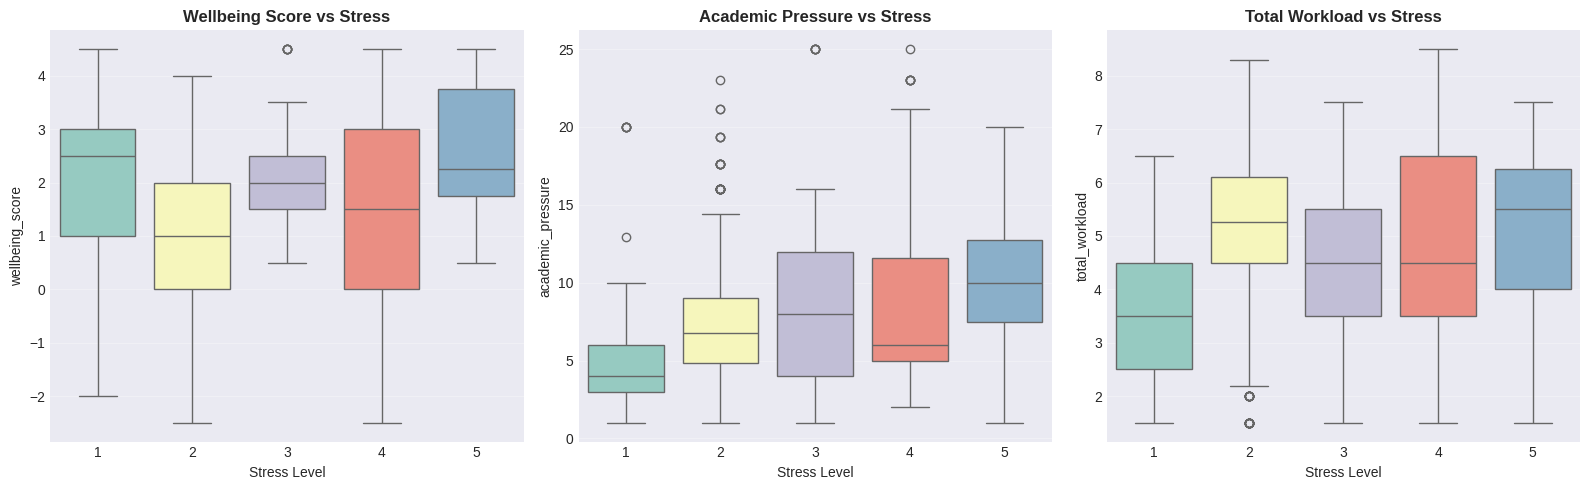


Engineered Features Correlation with Stress:
wellbeing_score: 0.140
academic_pressure: 0.261
total_workload: 0.114


In [30]:
# Analyze engineered features if they exist
if 'wellbeing_score' in combined_df.columns:
    engineered_features = ['wellbeing_score', 'academic_pressure', 'total_workload']
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    for idx, feature in enumerate(engineered_features):
        sns.boxplot(data=combined_df, x='stress_level', y=feature, ax=axes[idx], palette='Set3')
        axes[idx].set_title(f'{feature.replace("_", " ").title()} vs Stress', 
                           fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('Stress Level')
        axes[idx].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('engineered_features_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nEngineered Features Correlation with Stress:")
    for feature in engineered_features:
        corr = combined_df[feature].corr(combined_df['stress_level'])
        print(f"{feature}: {corr:.3f}")

## 8. Scatter Plot Matrix

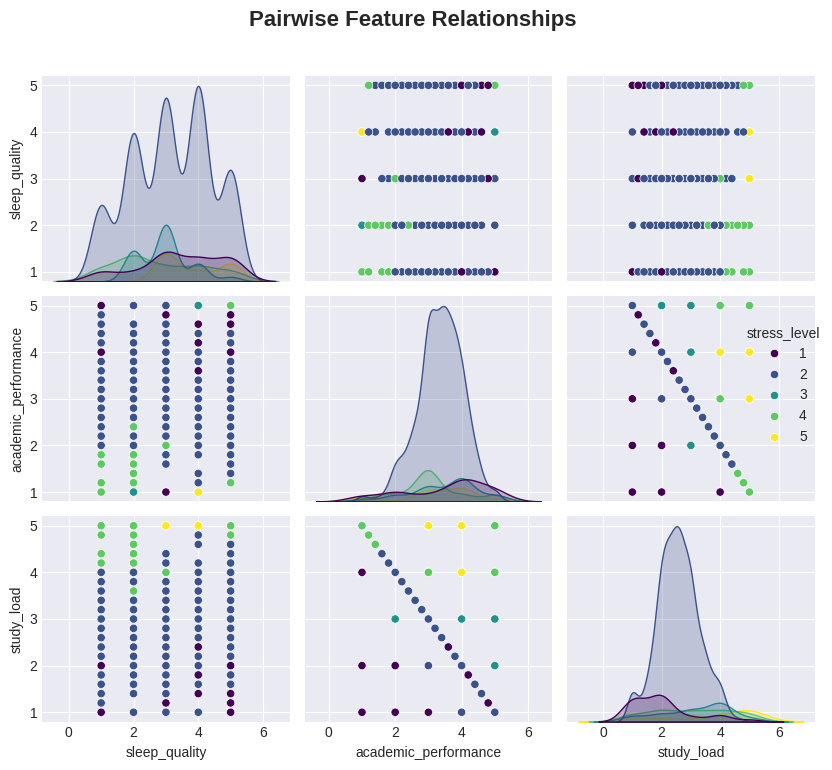

In [31]:
# Pairplot for key features
key_features = ['sleep_quality', 'academic_performance', 'study_load', 'stress_level']
sns.pairplot(combined_df[key_features], hue='stress_level', palette='viridis', diag_kind='kde', height=2.5)
plt.suptitle('Pairwise Feature Relationships', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('pairplot_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Statistical Tests

In [32]:
# ANOVA test for each feature vs stress level
print("=== ANOVA Tests (Feature vs Stress Level) ===")
print("Testing if features significantly differ across stress levels\n")

for feature in numeric_features:
    groups = [combined_df[combined_df['stress_level'] == level][feature].values 
              for level in sorted(combined_df['stress_level'].unique())]
    
    f_stat, p_value = stats.f_oneway(*groups)
    
    significance = "***" if p_value < 0.001 else "**" if p_value < 0.01 else "*" if p_value < 0.05 else "ns"
    print(f"{feature:30s} | F-stat: {f_stat:8.3f} | p-value: {p_value:.4e} {significance}")

print("\n*** p < 0.001, ** p < 0.01, * p < 0.05, ns = not significant")

=== ANOVA Tests (Feature vs Stress Level) ===
Testing if features significantly differ across stress levels

sleep_quality                  | F-stat:   12.155 | p-value: 1.0368e-09 ***
headaches_per_week             | F-stat:  122.375 | p-value: 3.0598e-89 ***
academic_performance           | F-stat:    4.801 | p-value: 7.5626e-04 ***
study_load                     | F-stat:   64.868 | p-value: 3.0193e-50 ***
extracurricular_frequency      | F-stat:  141.810 | p-value: 2.3826e-101 ***

*** p < 0.001, ** p < 0.01, * p < 0.05, ns = not significant


## 10. Dataset Comparison

=== Feature Means by Dataset Source ===
                      sleep_quality  headaches_per_week  academic_performance  \
dataset_source                                                                  
comprehensive_stress       3.213523            4.951364              3.363227   
student_factors            3.125000            2.182692              3.326923   

                      study_load  extracurricular_frequency  
dataset_source                                               
comprehensive_stress    2.636773                   5.500989  
student_factors         2.750000                   2.682692  


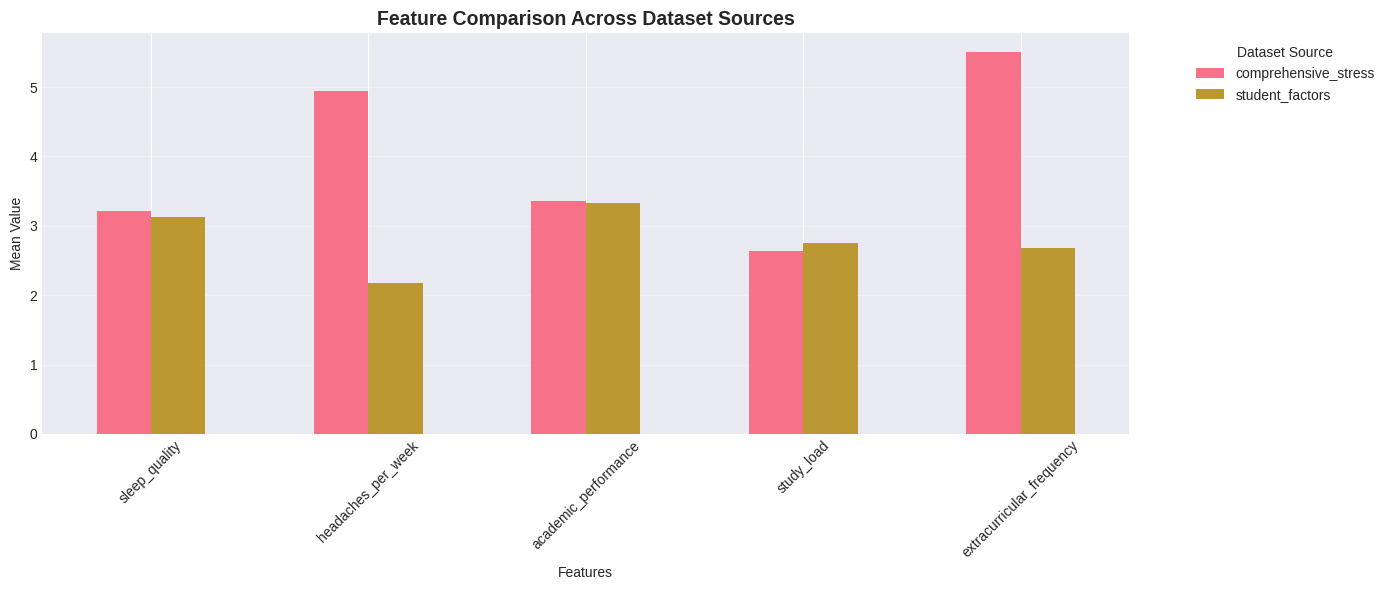

In [33]:
# Compare feature means across different dataset sources
print("=== Feature Means by Dataset Source ===")
comparison = combined_df.groupby('dataset_source')[numeric_features].mean()
print(comparison)

# Visualize comparison
comparison.T.plot(kind='bar', figsize=(14, 6), rot=45)
plt.title('Feature Comparison Across Dataset Sources', fontsize=14, fontweight='bold')
plt.xlabel('Features')
plt.ylabel('Mean Value')
plt.legend(title='Dataset Source', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('dataset_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 10.5 User-Contributed Data Analysis

In [34]:
# Analyze user-contributed data separately if it exists
if 'user_contributed' in combined_df['dataset_source'].values:
    user_data = combined_df[combined_df['dataset_source'] == 'user_contributed']
    other_data = combined_df[combined_df['dataset_source'] != 'user_contributed']
    
    print("=" * 70)
    print("USER-CONTRIBUTED DATA ANALYSIS")
    print("=" * 70)
    print(f"\nTotal User Contributions: {len(user_data)}")
    print(f"Percentage of Total Dataset: {(len(user_data) / len(combined_df)) * 100:.2f}%")
    
    print("\nUser Data Stress Level Distribution:")
    print(user_data['stress_level'].value_counts().sort_index())
    
    print("\nUser Data Feature Statistics:")
    print(user_data[numeric_features].describe())
    
    # Compare user data with original datasets
    print("\n--- Comparison: User Data vs Original Datasets ---")
    comparison_stats = pd.DataFrame({
        'User Contributed': user_data[numeric_features + ['stress_level']].mean(),
        'Original Datasets': other_data[numeric_features + ['stress_level']].mean()
    })
    print(comparison_stats)
    
    # Visualize the comparison
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    for idx, feature in enumerate(numeric_features + ['stress_level']):
        data_to_plot = [user_data[feature].values, other_data[feature].values]
        axes[idx].boxplot(data_to_plot, labels=['User Contributed', 'Original Datasets'])
        axes[idx].set_title(f'{feature.replace("_", " ").title()}', fontsize=11, fontweight='bold')
        axes[idx].set_ylabel('Value')
        axes[idx].grid(axis='y', alpha=0.3)
    
    plt.suptitle('User-Contributed Data vs Original Datasets Comparison', 
                 fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.savefig('user_data_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Time-based analysis if timestamp exists
    if 'timestamp' in user_data.columns:
        print("\n--- User Contribution Timeline ---")
        user_data_time = user_data.copy()
        user_data_time['timestamp'] = pd.to_datetime(user_data_time['timestamp'])
        user_data_time = user_data_time.sort_values('timestamp')
        
        if len(user_data_time) > 0:
            print(f"First contribution: {user_data_time['timestamp'].min()}")
            print(f"Latest contribution: {user_data_time['timestamp'].max()}")
            
            # Plot contribution timeline
            plt.figure(figsize=(12, 5))
            user_data_time['timestamp'].value_counts().sort_index().plot(kind='line', marker='o')
            plt.title('User Contributions Over Time', fontsize=14, fontweight='bold')
            plt.xlabel('Date')
            plt.ylabel('Number of Contributions')
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.savefig('user_contributions_timeline.png', dpi=300, bbox_inches='tight')
            plt.show()
    
    print("\n✓ User data analysis complete!")
    
else:
    print("=" * 70)
    print("NO USER-CONTRIBUTED DATA YET")
    print("=" * 70)
    print("\nUser contributions will appear here once data is submitted via the API.")
    print("The system is ready to incorporate user data into training and analysis.")

NO USER-CONTRIBUTED DATA YET

User contributions will appear here once data is submitted via the API.
The system is ready to incorporate user data into training and analysis.


## 11. Summary Statistics

In [35]:
# Generate comprehensive summary
print("=" * 70)
print("MULTI-DATASET ANALYSIS SUMMARY")
print("=" * 70)

print(f"\nTotal Samples: {len(combined_df):,}")
print(f"Total Features: {len(combined_df.columns) - 2}")  # Excluding target and source

print("\nDataset Composition:")
for source, count in combined_df['dataset_source'].value_counts().items():
    percentage = (count / len(combined_df)) * 100
    print(f"  {source}: {count:,} samples ({percentage:.1f}%)")

print("\nStress Level Distribution:")
for level, count in sorted(combined_df['stress_level'].value_counts().items()):
    percentage = (count / len(combined_df)) * 100
    print(f"  Level {int(level)}: {count:,} samples ({percentage:.1f}%)")

print("\nKey Statistics:")
print(f"  Average Stress Level: {combined_df['stress_level'].mean():.2f}")
print(f"  Median Stress Level: {combined_df['stress_level'].median():.2f}")
print(f"  Stress Level Std Dev: {combined_df['stress_level'].std():.2f}")

print("\n" + "=" * 70)

MULTI-DATASET ANALYSIS SUMMARY

Total Samples: 1,363
Total Features: 8

Dataset Composition:
  comprehensive_stress: 843 samples (61.8%)
  student_factors: 520 samples (38.2%)

Stress Level Distribution:
  Level 1: 153 samples (11.2%)
  Level 2: 873 samples (64.0%)
  Level 3: 125 samples (9.2%)
  Level 4: 132 samples (9.7%)
  Level 5: 80 samples (5.9%)

Key Statistics:
  Average Stress Level: 2.35
  Median Stress Level: 2.00
  Stress Level Std Dev: 1.00



## 12. Export Visualization Summary

In [36]:
# Create a summary report
summary_stats = {
    'Total Samples': len(combined_df),
    'Number of Features': len(numeric_features),
    'Average Stress Level': combined_df['stress_level'].mean(),
    'Most Common Stress Level': combined_df['stress_level'].mode()[0],
    'Dataset Sources': len(combined_df['dataset_source'].unique())
}

summary_df = pd.DataFrame([summary_stats])
summary_df.to_csv('analysis_summary.csv', index=False)
print("✓ Analysis summary exported to 'analysis_summary.csv'")

print("\n🎉 Multi-dataset analysis complete!")
print("All visualizations have been saved as PNG files.")

✓ Analysis summary exported to 'analysis_summary.csv'

🎉 Multi-dataset analysis complete!
All visualizations have been saved as PNG files.
